# External Economic Signals — REER

This notebook evaluates whether reporter-specific Real Effective Exchange Rate (REER) information improves March 2026 forecasts from the selected XGBoost and LSTM models. The existing forecasting cohorts, targets and model-selection decisions are retained. Trade-only reference scores come from notebooks 11 and 12; only the selected REER variants are trained here.

## 1. Load Results and Project Settings

Use the existing data loaders and evaluation utility. March remains the held-out target. Architectures and XGBoost settings come from the February validation decisions; the REER LSTM selects its own training duration using the same validation and early-stopping procedure as notebook 12. All REER outputs are saved under results/reer/: the comparison CSV, the sMAPE bar chart and the relative-change heatmap.


In [1]:
from pathlib import Path
import sys
import ast
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from bs4 import BeautifulSoup
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.dataset_loading import (
    load_forecasting_data, load_feature_data,
    COUNTRY_PREFIXES, SERIES_KEYS, TARGET, DATA_DIR,
)
from src.evaluation import evaluate_forecasts

RESULTS_DIR = PROJECT_ROOT / "results"
OUTPUT_DIR = RESULTS_DIR / "reer"
TEST_MONTH = pd.Timestamp("2026-03-01")
TRAIN_END = pd.Timestamp("2026-02-01")
VALIDATION_MONTH = TRAIN_END
REER_LAG_MONTHS = 2
SEQUENCE_LENGTH = 12
BATCH_SIZE = 256
RANDOM_SEED = 42
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(2)

ID_COLUMNS = SERIES_KEYS + ["Month"]
TRADE_FEATURES = [
    "lag_1", "lag_2", "lag_3", "lag_6", "lag_12",
    "rolling_mean_3", "rolling_mean_6", "rolling_mean_12",
    "rolling_std_3", "rolling_std_6", "rolling_std_12",
    "month_of_year", "month_sin", "month_cos",
]
LSTM_FEATURES = [TARGET, "month_of_year", "month_sin", "month_cos"]

original_results = {
    "XGBoost": pd.read_csv(RESULTS_DIR / "xgboost_results.csv"),
    "LSTM": pd.read_csv(RESULTS_DIR / "lstm_results.csv"),
}
for model_name, table in original_results.items():
    assert not table.Country.duplicated().any()
    assert set(table.Country) == set(COUNTRY_PREFIXES)
    assert table["Forecast Month"].eq("2026-03").all()

print(f"Device: {DEVICE}")
print("March reference results:")
display(pd.concat(original_results.values(), ignore_index=True))


Device: cpu
March reference results:


,Country,Model,Forecast Month,N Series,MAE,RMSE,sMAPE (%)
0,Slovakia,XGBoost (XGBoost_1),2026-03,21973,3.548070e+05,5.700961e+06,88.860391
1,South Korea,XGBoost (XGBoost_3),2026-03,27823,2.013895e+06,5.278073e+07,101.690338
2,USA,XGBoost (XGBoost_3),2026-03,35843,4.326257e+06,9.880096e+07,79.029049
3,Slovakia,LSTM (LSTM_3),2026-03,21973,2.400967e+05,3.217984e+06,79.852074
4,South Korea,LSTM (LSTM_2),2026-03,27823,1.616569e+06,4.507207e+07,108.689753
5,USA,LSTM (LSTM_1),2026-03,35843,3.764889e+06,7.274987e+07,84.354281


## 2. Reuse the Selected Configurations

Read the configuration dictionaries and saved validation tables from notebooks 11 and 12 without executing their cells. Retain the selected architecture for each country. The original LSTM epoch counts describe the saved trade-only references; they do not cap REER training.

The REER model uses notebook 12's maximum training budget and patience, with a fresh February validation pass to select its own best epoch. No March results are used for architecture or epoch selection. Saved notebook outputs must be retained for the original selection records.


In [2]:
def read_notebook_setting(notebook_name, variable_name):
    """Read a literal setting from an existing notebook without running cells."""
    path = PROJECT_ROOT / "notebooks" / notebook_name
    notebook = json.loads(path.read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        if cell["cell_type"] != "code":
            continue
        for node in ast.walk(ast.parse("".join(cell["source"]))):
            if isinstance(node, ast.Assign):
                if any(isinstance(item, ast.Name) and item.id == variable_name
                       for item in node.targets):
                    return ast.literal_eval(node.value)
    raise ValueError(f"{variable_name} was not found in {notebook_name}.")


def read_validation_table(notebook_name, required_columns):
    """Read the displayed validation table already saved in a notebook."""
    path = PROJECT_ROOT / "notebooks" / notebook_name
    notebook = json.loads(path.read_text(encoding="utf-8"))
    for cell in notebook["cells"]:
        for output in cell.get("outputs", []):
            html = "".join(output.get("data", {}).get("text/html", []))
            for table in BeautifulSoup(html, "html.parser").find_all("table"):
                columns = [item.get_text(strip=True)
                           for item in table.select("thead th")]
                columns = [name for name in columns if name]
                if not set(required_columns).issubset(columns):
                    continue
                rows = [
                    [item.get_text(strip=True) for item in row.find_all("td")]
                    for row in table.select("tbody tr")
                ]
                return pd.DataFrame(rows, columns=columns)
    raise ValueError(
        f"Save {notebook_name} with its validation table outputs before "
        "running this comparison. No configuration is selected from March results."
    )


XGBOOST_CONFIGS = read_notebook_setting(
    "11_machine_learning_models.ipynb", "XGBOOST_CONFIGS"
)
LSTM_CONFIGS = read_notebook_setting("12_deep_model.ipynb", "LSTM_CONFIGS")

validation_tables = {
    "XGBoost": read_validation_table(
        "11_machine_learning_models.ipynb",
        ["Country", "Configuration", "Validation Month", "MAE"],
    ),
    "LSTM": read_validation_table(
        "12_deep_model.ipynb",
        ["Country", "Configuration", "Validation Month", "Validation MAE", "Best Epoch"],
    ),
}

LSTM_MAX_EPOCHS = read_notebook_setting("12_deep_model.ipynb", "EPOCHS")
LSTM_PATIENCE = read_notebook_setting("12_deep_model.ipynb", "PATIENCE")
assert LSTM_MAX_EPOCHS >= 1 and LSTM_PATIENCE >= 1
print(f"REER LSTM: up to {LSTM_MAX_EPOCHS} epochs; patience {LSTM_PATIENCE}")
selected_configurations = {}
reference_lstm_epochs = {}
selection_rows = []

for model_name, configurations in [
    ("XGBoost", XGBOOST_CONFIGS), ("LSTM", LSTM_CONFIGS)
]:
    selected_configurations[model_name] = {}
    table = validation_tables[model_name]
    score_column = "MAE" if model_name == "XGBoost" else "Validation MAE"
    table[score_column] = pd.to_numeric(table[score_column], errors="raise")
    assert table["Validation Month"].eq("2026-02").all()
    assert not table.duplicated(["Country", "Configuration"]).any()

    for country in COUNTRY_PREFIXES:
        saved = original_results[model_name].loc[
            original_results[model_name].Country.eq(country)
        ].iloc[0]
        config_name = str(saved.Model).split("(")[-1].rstrip(")")
        country_scores = table.loc[table.Country.eq(country)]
        assert set(country_scores.Configuration) == set(configurations)
        best_name = country_scores.sort_values(
            score_column, kind="stable"
        ).iloc[0].Configuration
        assert config_name == best_name, (
            f"{country}: saved March results and February selection disagree."
        )
        selected_configurations[model_name][country] = config_name
        epochs = None
        if model_name == "LSTM":
            epochs = int(country_scores.loc[
                country_scores.Configuration.eq(config_name), "Best Epoch"
            ].iloc[0])
            assert 1 <= epochs <= 15
            reference_lstm_epochs[country] = epochs
        selection_rows.append({
            "Country": country, "Model": model_name,
            "Configuration": config_name, "Trade-only epochs": epochs,
            "Parameters": configurations[config_name],
        })

display(pd.DataFrame(selection_rows))


REER LSTM: up to 15 epochs; patience 5


,Country,Model,Configuration,Trade-only epochs,Parameters
0,South Korea,XGBoost,XGBoost_3,NaN,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."
1,Slovakia,XGBoost,XGBoost_1,NaN,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
2,USA,XGBoost,XGBoost_3,NaN,"{'n_estimators': 300, 'max_depth': 8, 'learnin..."
3,South Korea,LSTM,LSTM_2,6.0,"{'hidden_size': 32, 'num_layers': 1, 'learning..."
4,Slovakia,LSTM,LSTM_3,1.0,"{'hidden_size': 32, 'num_layers': 2, 'learning..."
5,USA,LSTM,LSTM_1,9.0,"{'hidden_size': 16, 'num_layers': 1, 'learning..."


## 3. Inspect Monthly REER Data

The saved files contain BIS monthly, real, broad-basket indices for Korea (KR), Slovakia (SK) and the United States (US). Validate dates, monthly frequency, country codes, missing values and duplicate months before integration. The URLs below identify the source series; the experiment reads the downloaded files without fetching revised observations.

REER is aligned to the reporting country with a two-month reference lag: March uses January REER. No interpolation or backfilling is applied. This lag is an assumed availability allowance; current snapshots may include historical revisions.

In [3]:
REER_SOURCES = {
    "South Korea": {
        "area": "KR",
        "url": "https://stats.bis.org/api/v2/data/dataflow/BIS/WS_EER/1.0/M.R.B.KR?format=csv",
    },
    "Slovakia": {
        "area": "SK",
        "url": "https://stats.bis.org/api/v2/data/dataflow/BIS/WS_EER/1.0/M.R.B.SK?format=csv",
    },
    "USA": {
        "area": "US",
        "url": "https://stats.bis.org/api/v2/data/dataflow/BIS/WS_EER/1.0/M.R.B.US?format=csv",
    },
}
reer_data = {}
reer_summary = []

for country, prefix in COUNTRY_PREFIXES.items():
    path = DATA_DIR / "external_signals" / f"{prefix}_bis_reer.csv"
    raw = pd.read_csv(path)
    required = {"FREQ", "EER_TYPE", "EER_BASKET", "REF_AREA",
                "TIME_PERIOD", "OBS_VALUE"}
    assert required.issubset(raw.columns), f"Unexpected REER schema: {path}"
    assert raw.FREQ.eq("M").all()
    assert raw.EER_TYPE.eq("R").all() and raw.EER_BASKET.eq("B").all()
    assert raw.REF_AREA.eq(REER_SOURCES[country]["area"]).all()

    reer = pd.DataFrame({
        "REER_month": pd.to_datetime(raw.TIME_PERIOD, format="%Y-%m"),
        "REER": pd.to_numeric(raw.OBS_VALUE, errors="raise"),
    }).sort_values("REER_month").reset_index(drop=True)
    assert not reer.REER_month.duplicated().any()
    assert reer.notna().all().all() and np.isfinite(reer.REER).all()
    expected_months = pd.date_range(
        reer.REER_month.min(), reer.REER_month.max(), freq="MS"
    )
    assert np.array_equal(reer.REER_month.to_numpy(), expected_months.to_numpy())
    reer["Month"] = reer.REER_month + pd.DateOffset(months=REER_LAG_MONTHS)
    reer_data[country] = reer
    reer_summary.append({
        "Country": country, "File": path.name, "Rows": len(reer),
        "First reference month": reer.REER_month.min(),
        "Last reference month": reer.REER_month.max(),
        "Missing values": int(reer.REER.isna().sum()),
        "Source URL": REER_SOURCES[country]["url"],
    })

display(pd.DataFrame(reer_summary))

,Country,File,Rows,First reference month,Last reference month,Missing values,Source URL
0,South Korea,korea_bis_reer.csv,393,1994-01-01,2026-09-01,0,https://stats.bis.org/api/v2/data/dataflow/BIS...
1,Slovakia,slovakia_bis_reer.csv,393,1994-01-01,2026-09-01,0,https://stats.bis.org/api/v2/data/dataflow/BIS...
2,USA,usa_bis_reer.csv,393,1994-01-01,2026-09-01,0,https://stats.bis.org/api/v2/data/dataflow/BIS...


## 4. Align Trade Observations and REER

Use the unchanged train/test files and existing March feature rows. Align both model comparisons to the exact saved March cohort, retaining zero-valued actuals. Validate monthly continuity and the February forecast origin. Load one country at a time to limit memory use; no feature or forecasting datasets are rewritten.

In [4]:
def add_reer(df, country):
    merged = df.merge(
        reer_data[country], on="Month", how="left",
        validate="many_to_one", sort=False,
    )
    pd.testing.assert_frame_equal(
        merged[ID_COLUMNS + [TARGET]],
        df[ID_COLUMNS + [TARGET]].reset_index(drop=True),
    )
    if merged.REER.isna().any():
        raise ValueError(f"{country}: missing lagged REER; no imputation is applied.")
    assert (
        merged.REER_month
        == merged.Month - pd.DateOffset(months=REER_LAG_MONTHS)
    ).all()
    return merged


def load_country_experiment(country):
    training, testing = load_forecasting_data([country])
    history = training[country].sort_values(
        SERIES_KEYS + ["Month"]
    ).reset_index(drop=True)
    target = testing[country].reset_index(drop=True)
    assert history.Month.max() == TRAIN_END and history.Month.lt(TEST_MONTH).all()
    assert target.Month.eq(TEST_MONTH).all()
    assert not history.duplicated(ID_COLUMNS).any()
    assert not target.duplicated(ID_COLUMNS).any()
    assert history[TARGET].notna().all() and history[TARGET].ge(0).all()
    assert target[TARGET].notna().all() and target[TARGET].ge(0).all()

    periods = history.Month.dt.year * 12 + history.Month.dt.month
    differences = periods.groupby(
        [history[key] for key in SERIES_KEYS], observed=True
    ).diff().dropna()
    assert differences.eq(1).all(), "A monthly gap was found in training data."
    assert history.groupby(SERIES_KEYS, observed=True).Month.max().eq(TRAIN_END).all()
    train_keys = history[SERIES_KEYS].drop_duplicates().sort_values(
        SERIES_KEYS
    ).reset_index(drop=True)
    test_keys = target[SERIES_KEYS].sort_values(SERIES_KEYS).reset_index(drop=True)
    pd.testing.assert_frame_equal(train_keys, test_keys)

    features = load_feature_data([country])[country]
    march_features = features.loc[features.Month.eq(TEST_MONTH)].drop(
        columns=[TARGET]
    )
    march = target.merge(
        march_features, on=ID_COLUMNS, how="left",
        validate="one_to_one", indicator=True,
    )
    assert march["_merge"].eq("both").all()
    march = march.drop(columns="_merge")
    assert march[TRADE_FEATURES].notna().all().all()
    pd.testing.assert_frame_equal(
        march[ID_COLUMNS + [TARGET]], target[ID_COLUMNS + [TARGET]]
    )
    for model_name in ["XGBoost", "LSTM"]:
        saved = original_results[model_name].loc[
            original_results[model_name].Country.eq(country)
        ].iloc[0]
        assert int(saved["N Series"]) == len(target), (
            "The saved reference and current March cohort have different sizes; "
            "a matched comparison requires the same observations."
        )
    return add_reer(history, country), add_reer(march, country)

## 5. Selected XGBoost Model with REER

Add the lagged REER value to the same fourteen trade and calendar predictors used in notebook 11. Refit the selected configuration through February and forecast March. The final fitting procedure retains initial missing lag features, which XGBoost handles natively, as in notebook 11. No additional tuning is performed.

In [5]:
def forecast_xgboost_reer(history, march, config):
    features = TRADE_FEATURES + ["REER"]
    model = XGBRegressor(
        **config,
        objective="reg:squarederror",
        tree_method="hist",
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_SEED,
        n_jobs=-1,
    )
    model.fit(history[features], history[TARGET])
    return np.maximum(model.predict(march[features]), 0.0)

## 6. Selected LSTM Model with REER

Retain notebook 12's twelve-month trade/calendar sequences, selected architecture, Huber loss and seeded shuffled batches. Add the REER scalar available at each target's forecast origin to the final LSTM hidden output.

Fit through January and evaluate February MAE in original trade-value units after each epoch. As in notebook 12, train for up to 15 epochs and stop after 5 consecutive epochs without improvement. The selected REER epoch may differ from the trade-only epoch. Only the architecture is held fixed.

Validation scalers are fitted through January. After epoch selection, initialize a fresh model and fit new scalers using observations through February, then train for the selected number of epochs before forecasting March. Predictions are inverse-standardized and transformed with expm1 exactly once.


In [6]:
class TradeSequenceDataset(Dataset):
    """The sequence construction from notebook 12, plus target-origin REER."""
    def __init__(self, df, feature_columns, target_column, target_month=None):
        self.series = []
        self.index = []
        for _, group in df.groupby(SERIES_KEYS, sort=False, observed=True):
            group = group.sort_values("Month").reset_index(drop=True)
            features = group[feature_columns].to_numpy(dtype=np.float32)
            targets = group[target_column].to_numpy(dtype=np.float32)
            external = group["REER"].to_numpy(dtype=np.float32)
            series_id = len(self.series)
            self.series.append((features, targets, external))
            for target_idx in range(SEQUENCE_LENGTH, len(group)):
                if target_month is None or group.Month.iloc[target_idx] == target_month:
                    self.index.append((series_id, target_idx))

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        series_id, target_idx = self.index[idx]
        features, targets, external = self.series[series_id]
        sequence = features[target_idx - SEQUENCE_LENGTH:target_idx]
        return (
            torch.from_numpy(sequence.copy()),
            torch.tensor(targets[target_idx], dtype=torch.float32),
            torch.tensor([external[target_idx]], dtype=torch.float32),
        )


class LSTMForecaster(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
        )
        self.output = nn.Linear(hidden_size + 1, 1)

    def forward(self, sequence, external):
        output, _ = self.lstm(sequence)
        combined = torch.cat([output[:, -1, :], external], dim=1)
        return self.output(combined).squeeze(-1)


def inverse_value(scaled_values, scaler):
    log_values = np.asarray(scaled_values) * scaler.scale_[0] + scaler.mean_[0]
    predictions = np.maximum(np.expm1(log_values), 0.0)
    if not np.isfinite(predictions).all():
        raise ValueError("Non-finite inverse-transformed LSTM predictions.")
    return predictions


def prepare_lstm_data(history, fit_end):
    """Fit scalers through fit_end; later rows are transformed only."""
    train_df = history[
        SERIES_KEYS + ["Month"] + LSTM_FEATURES + ["REER"]
    ].sort_values(SERIES_KEYS + ["Month"]).copy()
    train_df[TARGET] = np.log1p(train_df[TARGET])
    fitting_rows = train_df.loc[train_df.Month <= fit_end]
    if fitting_rows.empty:
        raise ValueError("No observations available for fitting LSTM scalers.")
    scaler = StandardScaler().fit(fitting_rows[LSTM_FEATURES])
    reer_scaler = StandardScaler().fit(
        fitting_rows[["Month", "REER"]].drop_duplicates("Month")[["REER"]]
    )
    scaled = train_df.copy()
    scaled[LSTM_FEATURES] = scaler.transform(train_df[LSTM_FEATURES])
    scaled["REER"] = reer_scaler.transform(train_df[["REER"]]).ravel()
    sample = np.array([0.0, 10.0, 1000.0])
    standardized = (np.log1p(sample) - scaler.mean_[0]) / scaler.scale_[0]
    assert np.allclose(inverse_value(standardized, scaler), sample)
    return scaled, scaler, reer_scaler


def build_lstm_model(config):
    torch.manual_seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    return LSTMForecaster(
        input_size=len(LSTM_FEATURES),
        hidden_size=config["hidden_size"],
        num_layers=config["num_layers"],
    ).to(DEVICE)


def train_one_epoch(model, loader, optimizer):
    model.train()
    criterion = nn.HuberLoss()
    for sequences, targets, external in loader:
        optimizer.zero_grad()
        predicted = model(sequences.to(DEVICE), external.to(DEVICE))
        loss = criterion(predicted, targets.to(DEVICE))
        loss.backward()
        optimizer.step()


def select_lstm_epochs(history, config):
    """Select REER training duration using February, never March."""
    history = history.loc[history.Month <= VALIDATION_MONTH]
    assert history.Month.max() == VALIDATION_MONTH
    fit_end = VALIDATION_MONTH - pd.DateOffset(months=1)
    scaled, scaler, _ = prepare_lstm_data(history, fit_end)
    training = TradeSequenceDataset(
        scaled.loc[scaled.Month < VALIDATION_MONTH], LSTM_FEATURES, TARGET
    )
    validation = TradeSequenceDataset(
        scaled, LSTM_FEATURES, TARGET, target_month=VALIDATION_MONTH
    )
    assert len(training) > 0
    assert len(validation) == int(history.Month.eq(VALIDATION_MONTH).sum())
    train_loader = DataLoader(
        training, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED),
    )
    val_loader = DataLoader(validation, batch_size=BATCH_SIZE, shuffle=False)
    model = build_lstm_model(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    best_mae, best_epoch, stale = float("inf"), 0, 0
    scores = []

    for epoch in range(LSTM_MAX_EPOCHS):
        train_one_epoch(model, train_loader, optimizer)
        model.eval()
        predictions, actuals = [], []
        with torch.no_grad():
            for sequences, targets, external in val_loader:
                predicted = model(sequences.to(DEVICE), external.to(DEVICE))
                predictions.append(predicted.cpu().numpy())
                actuals.append(targets.numpy())
        predictions = inverse_value(np.concatenate(predictions), scaler)
        actuals = inverse_value(np.concatenate(actuals), scaler)
        mae = float(np.abs(actuals - predictions).mean())
        scores.append({"Epoch": epoch + 1, "February MAE": mae})
        print(f"Epoch {epoch + 1}/{LSTM_MAX_EPOCHS} | February MAE: {mae:,.2f}")
        if mae < best_mae:
            best_mae, best_epoch, stale = mae, epoch + 1, 0
        else:
            stale += 1
            if stale >= LSTM_PATIENCE:
                print("Early stopping.")
                break
    if best_epoch == 0:
        raise ValueError("No finite February validation score.")
    return best_epoch, pd.DataFrame(scores)


def forecast_lstm_reer(history, march, config, epochs):
    """Fresh refit through February using the REER-selected epoch count."""
    assert history.Month.max() == TRAIN_END and history.Month.lt(TEST_MONTH).all()
    assert int(epochs) >= 1
    scaled_train, scaler, reer_scaler = prepare_lstm_data(history, TRAIN_END)
    march_reer = reer_scaler.transform(march[["REER"]]).astype(np.float32)
    dataset = TradeSequenceDataset(scaled_train, LSTM_FEATURES, TARGET)
    if len(dataset) == 0:
        raise ValueError("No eligible LSTM training sequences.")
    loader = DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True,
        generator=torch.Generator().manual_seed(RANDOM_SEED),
    )
    model = build_lstm_model(config)
    optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])
    print(f"Refitting through February for {epochs} selected epochs.")
    for epoch in range(int(epochs)):
        train_one_epoch(model, loader, optimizer)
        print(f"Refit epoch {epoch + 1}/{epochs} completed.")

    # Preserve the target order, rather than relying on group iteration order.
    groups = {
        key: group for key, group in scaled_train.groupby(
            SERIES_KEYS, sort=False, observed=True
        )
    }
    windows = []
    expected_months = pd.date_range(
        TEST_MONTH - pd.DateOffset(months=SEQUENCE_LENGTH),
        periods=SEQUENCE_LENGTH, freq="MS",
    )
    for key in march[SERIES_KEYS].itertuples(index=False, name=None):
        tail = groups[key].sort_values("Month").tail(SEQUENCE_LENGTH)
        assert np.array_equal(tail.Month.to_numpy(), expected_months.to_numpy())
        windows.append(tail[LSTM_FEATURES].to_numpy(dtype=np.float32))

    model.eval()
    scaled_predictions = []
    with torch.no_grad():
        for start in range(0, len(windows), BATCH_SIZE):
            stop = start + BATCH_SIZE
            sequences = torch.tensor(np.asarray(windows[start:stop])).to(DEVICE)
            external = torch.tensor(march_reer[start:stop]).to(DEVICE)
            scaled_predictions.append(model(sequences, external).cpu().numpy())
    return inverse_value(np.concatenate(scaled_predictions), scaler)


## 7. March 2026 REER Forecasts

Train only the selected REER variants. Original trade-only scores are reused from the saved results, with the same March cohort sizes and current actual-value files. Models and keyed original predictions were not saved, so the comparison cannot independently verify the original predictions row by row. If the forecasting datasets have changed since notebooks 11 and 12 ran, their reference scores must be regenerated before comparison.

In [7]:
comparison_metrics = []
reer_predictions = {}
lstm_reer_validation = {}

for country in COUNTRY_PREFIXES:
    print(f"\n{'=' * 15} {country} {'=' * 15}")
    history, march = load_country_experiment(country)

    for model_name in ["XGBoost", "LSTM"]:
        config_name = selected_configurations[model_name][country]
        original_epochs = reference_lstm_epochs[country] if model_name == "LSTM" else None
        epochs = None
        print(f"{model_name}: {config_name}; {len(march):,} March series")
        if model_name == "XGBoost":
            predicted = forecast_xgboost_reer(
                history, march, XGBOOST_CONFIGS[config_name]
            )
        else:
            epochs, epoch_scores = select_lstm_epochs(history, LSTM_CONFIGS[config_name])
            lstm_reer_validation[country] = epoch_scores
            print(f"Selected REER epoch: {epochs}")
            display(epoch_scores)
            predicted = forecast_lstm_reer(
                history, march, LSTM_CONFIGS[config_name], epochs
            )
        assert len(predicted) == len(march) and np.isfinite(predicted).all()

        reference = original_results[model_name].loc[
            original_results[model_name].Country.eq(country)
        ].iloc[0].to_dict()
        reference.update(
            Model=model_name, Configuration=config_name, Epochs=original_epochs,
            Features="trade_only", Source="Saved benchmark",
        )
        comparison_metrics.append(reference)

        enhanced = evaluate_forecasts(
            country, model_name, march[TARGET], predicted, "2026-03"
        )
        enhanced.update(
            Configuration=config_name, Epochs=epochs,
            Features="trade_reer", Source="REER experiment",
        )
        comparison_metrics.append(enhanced)

        # Keep keyed predictions in memory only; no additional result files.
        frame = march[ID_COLUMNS + [TARGET]].copy()
        frame["Prediction"] = predicted
        reer_predictions[(country, model_name)] = frame
        display(pd.DataFrame([reference, enhanced]))

    del history, march

metrics = pd.DataFrame(comparison_metrics)



=============== South Korea ===============
XGBoost: XGBoost_3; 27,823 March series


,Country,Model,Forecast Month,N Series,MAE,RMSE,sMAPE (%),Configuration,Epochs,Features,Source
0,South Korea,XGBoost,2026-03,27823,2.013895e+06,5.278073e+07,101.690338,XGBoost_3,None,trade_only,Saved benchmark
1,South Korea,XGBoost,2026-03,27823,2.178463e+06,5.132341e+07,101.630860,XGBoost_3,None,trade_reer,REER experiment


LSTM: LSTM_2; 27,823 March series
Epoch 1/15 | February MAE: 1,642,808.18
Epoch 2/15 | February MAE: 1,490,928.11
Epoch 3/15 | February MAE: 1,498,466.39
Epoch 4/15 | February MAE: 1,139,856.34
Epoch 5/15 | February MAE: 1,165,775.03
Epoch 6/15 | February MAE: 1,348,449.61
Epoch 7/15 | February MAE: 1,215,475.38
Epoch 8/15 | February MAE: 1,163,160.52
Epoch 9/15 | February MAE: 1,075,784.64
Epoch 10/15 | February MAE: 1,117,814.76
Epoch 11/15 | February MAE: 1,351,320.43
Epoch 12/15 | February MAE: 1,464,467.57
Epoch 13/15 | February MAE: 1,510,935.81
Epoch 14/15 | February MAE: 1,222,759.78
Early stopping.
Selected REER epoch: 9


,Epoch,February MAE
0,1,1.642808e+06
1,2,1.490928e+06
2,3,1.498466e+06
3,4,1.139856e+06
4,5,1.165775e+06
5,6,1.348450e+06
6,7,1.215475e+06
7,8,1.163161e+06
8,9,1.075785e+06
9,10,1.117815e+06


Refitting through February for 9 selected epochs.
Refit epoch 1/9 completed.
Refit epoch 2/9 completed.
Refit epoch 3/9 completed.
Refit epoch 4/9 completed.
Refit epoch 5/9 completed.
Refit epoch 6/9 completed.
Refit epoch 7/9 completed.
Refit epoch 8/9 completed.
Refit epoch 9/9 completed.


,Country,Model,Forecast Month,N Series,MAE,RMSE,sMAPE (%),Configuration,Epochs,Features,Source
0,South Korea,LSTM,2026-03,27823,1.616569e+06,4.507207e+07,108.689753,LSTM_2,6,trade_only,Saved benchmark
1,South Korea,LSTM,2026-03,27823,1.919115e+06,4.789223e+07,109.007555,LSTM_2,9,trade_reer,REER experiment


... (8 outputs left out)

LSTM: LSTM_1; 35,843 March series
Epoch 1/15 | February MAE: 4,207,123.76
Epoch 2/15 | February MAE: 4,068,878.00
Epoch 3/15 | February MAE: 3,241,800.53
Epoch 4/15 | February MAE: 3,554,789.76
Epoch 5/15 | February MAE: 3,248,784.23
Epoch 6/15 | February MAE: 3,220,007.03
Epoch 7/15 | February MAE: 3,295,512.84
Epoch 8/15 | February MAE: 3,513,979.92
Epoch 9/15 | February MAE: 3,153,095.71
Epoch 10/15 | February MAE: 3,133,962.73
Epoch 11/15 | February MAE: 3,519,638.26
Epoch 12/15 | February MAE: 3,654,566.67
Epoch 13/15 | February MAE: 3,195,723.91
Epoch 14/15 | February MAE: 2,944,527.08
Epoch 15/15 | February MAE: 3,659,891.45
Selected REER epoch: 14


,Epoch,February MAE
0,1,4.207124e+06
1,2,4.068878e+06
2,3,3.241801e+06
3,4,3.554790e+06
4,5,3.248784e+06
5,6,3.220007e+06
6,7,3.295513e+06
7,8,3.513980e+06
8,9,3.153096e+06
9,10,3.133963e+06


Refitting through February for 14 selected epochs.
Refit epoch 1/14 completed.
Refit epoch 2/14 completed.
Refit epoch 3/14 completed.
Refit epoch 4/14 completed.
Refit epoch 5/14 completed.
Refit epoch 6/14 completed.
Refit epoch 7/14 completed.
Refit epoch 8/14 completed.
Refit epoch 9/14 completed.
Refit epoch 10/14 completed.
Refit epoch 11/14 completed.
Refit epoch 12/14 completed.
Refit epoch 13/14 completed.
Refit epoch 14/14 completed.


,Country,Model,Forecast Month,N Series,MAE,RMSE,sMAPE (%),Configuration,Epochs,Features,Source
0,USA,LSTM,2026-03,35843,3.764889e+06,7.274987e+07,84.354281,LSTM_1,9,trade_only,Saved benchmark
1,USA,LSTM,2026-03,35843,3.208260e+06,5.860955e+07,83.525315,LSTM_1,14,trade_reer,REER experiment


## 8. Matched Comparison and Results

Report trade-only and REER MAE, RMSE and sMAPE with the evaluated series counts. For each metric, differences are REER minus trade-only: negative values indicate improvement and positive values deterioration. MAE and RMSE differences retain trade-value units. The sMAPE difference is in percentage points; its relative percentage change is reported separately. Relative changes are undefined when the reference metric is zero.

The plot compares XGBoost and LSTM sMAPE (%). All outputs are saved under results/reer/: reer_comparison.csv, model_comparison.png and metric_changes_heatmap.png.


March accuracy: trade-only versus REER


,Country,Model,N Series,Trade-only MAE,MAE,Trade-only RMSE,RMSE,Trade-only sMAPE (%),sMAPE (%)
0,Slovakia,LSTM,21973,2.400967e+05,2.549293e+05,3.217984e+06,3.674987e+06,79.852074,81.512785
1,Slovakia,XGBoost,21973,3.548070e+05,6.034204e+05,5.700961e+06,7.225397e+06,88.860391,162.554461
2,South Korea,LSTM,27823,1.616569e+06,1.919115e+06,4.507207e+07,4.789223e+07,108.689753,109.007555
3,South Korea,XGBoost,27823,2.013895e+06,2.178463e+06,5.278073e+07,5.132341e+07,101.690338,101.630860
4,USA,LSTM,35843,3.764889e+06,3.208260e+06,7.274987e+07,5.860955e+07,84.354281,83.525315
5,USA,XGBoost,35843,4.326257e+06,4.254407e+06,9.880096e+07,9.928193e+07,79.029049,78.278979


Changes relative to trade-only; negative values indicate lower errors


,Country,Model,MAE difference,MAE change (%),RMSE difference,RMSE change (%),sMAPE difference (pp),sMAPE change (%),Metric agreement
0,Slovakia,LSTM,14832.625386,6.177772,4.570024e+05,14.201512,1.660711,2.079734,All worsen
1,Slovakia,XGBoost,248613.448644,70.070058,1.524435e+06,26.739966,73.694070,82.932417,All worsen
2,South Korea,LSTM,302546.154858,18.715328,2.820163e+06,6.257007,0.317802,0.292393,All worsen
3,South Korea,XGBoost,164568.217951,8.171639,-1.457318e+06,-2.761080,-0.059478,-0.058490,Mixed
4,USA,LSTM,-556628.991576,-14.784738,-1.414032e+07,-19.436901,-0.828966,-0.982719,All improve
5,USA,XGBoost,-71850.396475,-1.660798,4.809695e+05,0.486807,-0.750070,-0.949107,Mixed


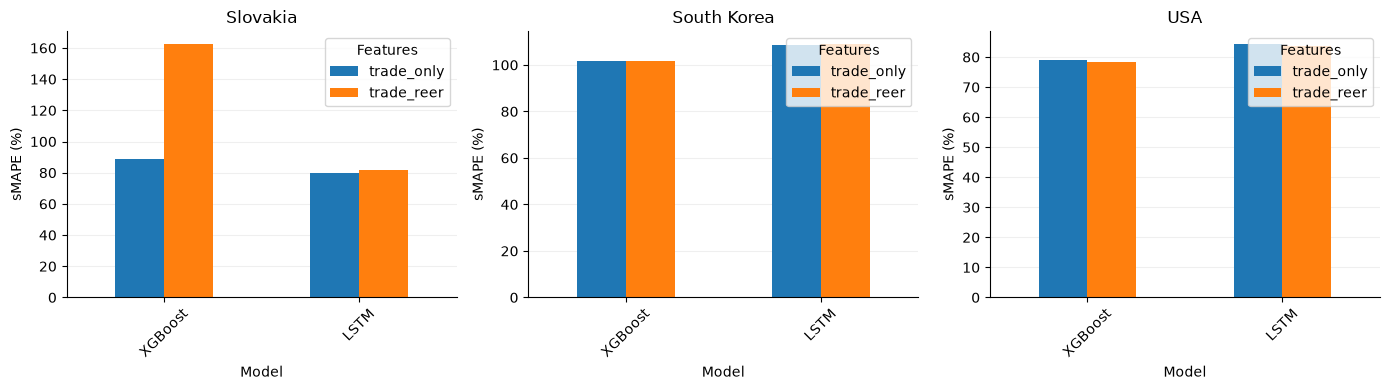

Saved comparison table and plot to: c:\Transfer\InterdisciplinaryProject\results\reer


In [8]:
keys = ["Country", "Model", "Forecast Month", "Configuration"]
reference = metrics.loc[metrics.Features.eq("trade_only")].copy()
reference = reference[
    keys + ["N Series", "MAE", "RMSE", "sMAPE (%)", "Epochs"]
].rename(columns={
    "Epochs": "Trade-only Epochs",
    "N Series": "Trade-only N Series",
    "MAE": "Trade-only MAE",
    "RMSE": "Trade-only RMSE",
    "sMAPE (%)": "Trade-only sMAPE (%)",
})
comparison = metrics.loc[metrics.Features.eq("trade_reer")].merge(
    reference, on=keys, validate="one_to_one"
)
assert comparison["N Series"].eq(comparison["Trade-only N Series"]).all()
assert len(comparison) == len(COUNTRY_PREFIXES) * 2

metric_columns = [
    ("MAE", "Trade-only MAE", "MAE difference", "MAE change (%)", "MAE outcome"),
    ("RMSE", "Trade-only RMSE", "RMSE difference", "RMSE change (%)", "RMSE outcome"),
    ("sMAPE (%)", "Trade-only sMAPE (%)", "sMAPE difference (pp)",
     "sMAPE change (%)", "sMAPE outcome"),
]
for metric, baseline, difference, relative_change, outcome in metric_columns:
    comparison[difference] = comparison[metric] - comparison[baseline]
    comparison[relative_change] = (
        100 * comparison[difference] / comparison[baseline].replace(0, np.nan)
    )
    comparison[outcome] = np.select(
        [comparison[difference] < 0, comparison[difference] > 0],
        ["Improves", "Worsens"], default="Unchanged",
    )

outcomes = comparison[["MAE outcome", "RMSE outcome", "sMAPE outcome"]]
comparison["Metric agreement"] = np.select(
    [outcomes.eq("Improves").all(axis=1),
     outcomes.eq("Worsens").all(axis=1),
     outcomes.eq("Unchanged").all(axis=1)],
    ["All improve", "All worsen", "All unchanged"], default="Mixed",
)
comparison = comparison.sort_values(["Country", "Model"]).reset_index(drop=True)

fig, axes = plt.subplots(1, len(COUNTRY_PREFIXES), figsize=(14, 4), squeeze=False)
for ax, (country, group) in zip(axes.ravel(), metrics.groupby("Country")):
    table = group.pivot(
        index="Model", columns="Features", values="sMAPE (%)"
    ).reindex(["XGBoost", "LSTM"])
    table[["trade_only", "trade_reer"]].plot.bar(ax=ax, rot=45)
    ax.set_title(country)
    ax.set_ylabel("sMAPE (%)")
    ax.set_xlabel("Model")
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.2)
fig.tight_layout()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
comparison.to_csv(OUTPUT_DIR / "reer_comparison.csv", index=False)
fig.savefig(OUTPUT_DIR / "model_comparison.png", dpi=150, bbox_inches="tight")
print("March accuracy: trade-only versus REER")
display(comparison[
    ["Country", "Model", "N Series", "Trade-only MAE", "MAE",
     "Trade-only RMSE", "RMSE", "Trade-only sMAPE (%)", "sMAPE (%)"]
])
print("Changes relative to trade-only; negative values indicate lower errors")
display(comparison[
    ["Country", "Model", "MAE difference", "MAE change (%)",
     "RMSE difference", "RMSE change (%)", "sMAPE difference (pp)",
     "sMAPE change (%)", "Metric agreement"]
])
display(fig)
plt.close(fig)
print(f"Saved comparison table and plot to: {OUTPUT_DIR}")


## 9. Comparison Across Countries and Models

Use sMAPE as the primary reporting metric and inspect MAE and RMSE for agreement or trade-offs. The tables below show each metric's direction and compare relative changes across countries and models. Raw trade-value errors are not averaged across countries, because their scales and source units differ.

The printed findings describe March 2026 only. They do not establish statistical significance, causation or improvement in future months.


In [9]:
display(comparison[
    ["Country", "Model", "N Series", "MAE outcome", "RMSE outcome",
     "sMAPE outcome", "Metric agreement"]
])

country_model_changes = comparison.pivot(
    index="Country", columns="Model",
    values=["MAE change (%)", "RMSE change (%)", "sMAPE change (%)"],
)
print("Relative error changes by country and model (%)")
display(country_model_changes)

for model_name, group in comparison.groupby("Model"):
    improved = int(group["sMAPE outcome"].eq("Improves").sum())
    worsened = int(group["sMAPE outcome"].eq("Worsens").sum())
    unchanged = int(group["sMAPE outcome"].eq("Unchanged").sum())
    print(
        f"March 2026, {model_name}: REER lowered sMAPE in {improved} of "
        f"{len(group)} countries, increased it in {worsened}, "
        f"and left it unchanged in {unchanged}."
    )

for _, row in comparison.iterrows():
    relative = row["sMAPE change (%)"]
    relative_text = (
        f"{relative:+.2f}% relative change"
        if pd.notna(relative)
        else "relative change undefined because trade-only sMAPE is zero"
    )
    print(
        f"{row['Country']} - {row['Model']}: sMAPE "
        f"{row['Trade-only sMAPE (%)']:.2f}% -> {row['sMAPE (%)']:.2f}%; "
        f"{row['sMAPE difference (pp)']:+.2f} percentage points "
        f"({relative_text}). Metrics: {row['Metric agreement'].lower()}."
    )



,Country,Model,N Series,MAE outcome,RMSE outcome,sMAPE outcome,Metric agreement
0,Slovakia,LSTM,21973,Worsens,Worsens,Worsens,All worsen
1,Slovakia,XGBoost,21973,Worsens,Worsens,Worsens,All worsen
2,South Korea,LSTM,27823,Worsens,Worsens,Worsens,All worsen
3,South Korea,XGBoost,27823,Worsens,Improves,Improves,Mixed
4,USA,LSTM,35843,Improves,Improves,Improves,All improve
5,USA,XGBoost,35843,Improves,Worsens,Improves,Mixed


Relative error changes by country and model (%)


MAE change (%)            RMSE change (%)             \
Model                 LSTM    XGBoost            LSTM    XGBoost   
Country                                                            
Slovakia          6.177772  70.070058       14.201512  26.739966   
South Korea      18.715328   8.171639        6.257007  -2.761080   
USA             -14.784738  -1.660798      -19.436901   0.486807   

            sMAPE change (%)             
Model                   LSTM    XGBoost  
Country                                  
Slovakia            2.079734  82.932417  
South Korea         0.292393  -0.058490  
USA                -0.982719  -0.949107

March 2026, LSTM: REER lowered sMAPE in 1 of 3 countries, increased it in 2, and left it unchanged in 0.
March 2026, XGBoost: REER lowered sMAPE in 2 of 3 countries, increased it in 1, and left it unchanged in 0.
Slovakia - LSTM: sMAPE 79.85% -> 81.51%; +1.66 percentage points (+2.08% relative change). Metrics: all worsen.
Slovakia - XGBoost: sMAPE 88.86% -> 162.55%; +73.69 percentage points (+82.93% relative change). Metrics: all worsen.
South Korea - LSTM: sMAPE 108.69% -> 109.01%; +0.32 percentage points (+0.29% relative change). Metrics: all worsen.
South Korea - XGBoost: sMAPE 101.69% -> 101.63%; -0.06 percentage points (-0.06% relative change). Metrics: mixed.
USA - LSTM: sMAPE 84.35% -> 83.53%; -0.83 percentage points (-0.98% relative change). Metrics: all improve.
USA - XGBoost: sMAPE 79.03% -> 78.28%; -0.75 percentage points (-0.95% relative change). Metrics: mixed.


## 10. Relative Error Changes Across Metrics

The heatmap compares percentage changes in MAE, RMSE and sMAPE across the six country-model combinations. Negative changes mean lower error with REER and appear green; positive changes appear red. A common symmetric scale is centered at zero, and cell labels retain the actual percentage changes.

A relative change is undefined when the trade-only metric is zero; such cells are marked N/A. The figure describes the observed March comparison and does not indicate statistical significance. Like the other REER outputs, it is saved under results/reer/.


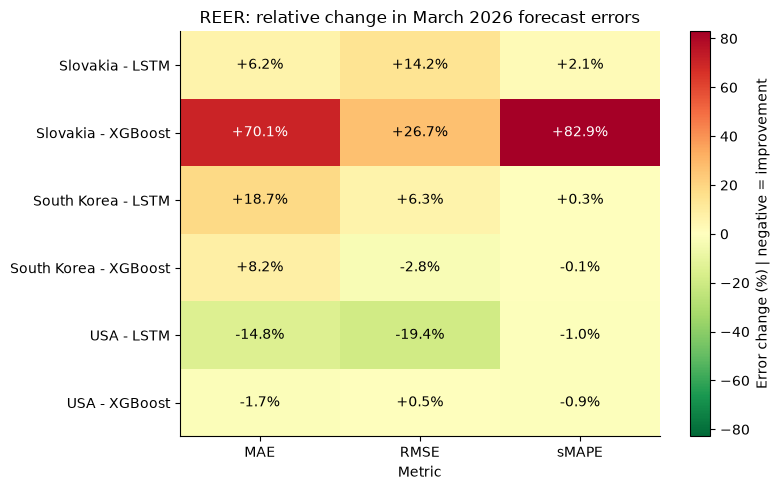

Saved relative-change heatmap to: c:\Transfer\InterdisciplinaryProject\results\reer\metric_changes_heatmap.png


In [10]:
change_columns = ["MAE change (%)", "RMSE change (%)", "sMAPE change (%)"]
heatmap_data = comparison.set_index(["Country", "Model"])[change_columns].sort_index()
heatmap_values = heatmap_data.to_numpy(dtype=float)
finite_values = heatmap_values[np.isfinite(heatmap_values)]
color_limit = max(float(np.abs(finite_values).max()), 1.0) if finite_values.size else 1.0

colors = plt.get_cmap("RdYlGn_r").copy()
colors.set_bad("#eeeeee")
fig, ax = plt.subplots(figsize=(8, 5))
image = ax.imshow(
    np.ma.masked_invalid(heatmap_values),
    cmap=colors, vmin=-color_limit, vmax=color_limit, aspect="auto",
)
ax.set_xticks(range(len(change_columns)))
ax.set_xticklabels(["MAE", "RMSE", "sMAPE"])
ax.set_yticks(range(len(heatmap_data)))
ax.set_yticklabels([f"{country} - {model}" for country, model in heatmap_data.index])
ax.set_title("REER: relative change in March 2026 forecast errors")
ax.set_xlabel("Metric")
for row in range(heatmap_values.shape[0]):
    for column in range(heatmap_values.shape[1]):
        value = heatmap_values[row, column]
        label = f"{value:+.1f}%" if np.isfinite(value) else "N/A"
        text_color = "white" if np.isfinite(value) and abs(value) > 0.65 * color_limit else "black"
        ax.text(column, row, label, ha="center", va="center", color=text_color)
colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Error change (%) | negative = improvement")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(OUTPUT_DIR / "metric_changes_heatmap.png", dpi=150, bbox_inches="tight")
display(fig)
plt.close(fig)
print(f"Saved relative-change heatmap to: {OUTPUT_DIR / 'metric_changes_heatmap.png'}")



## Summary

The experiment compares the selected trade-only benchmarks with matched REER-enhanced March forecasts. The added signal is evaluated rather than assumed to improve accuracy. Only the selected REER configurations are fitted; baseline models, statistical models and architecture searches are not repeated. The REER LSTM repeats only epoch selection on February, using the same early-stopping protocol as the trade-only experiment.

Interpretation is limited by a single test month, revised REER snapshots, assumed preceding-month trade availability, and the existing retrospective cohort selection in the preparation notebooks. Saved original scores lack keyed prediction files, so cohort sizes and the unchanged source datasets support comparability, while an independent paired forecast audit is unavailable. The results describe predictive contribution, not a causal exchange-rate effect.


## 11. RQ2 — Interpretation of External-Signal Results

**Do auxiliary data sources improve forecast accuracy?**

This research question examines whether information beyond historical trade and calendar features improves forecast accuracy. REER is the auxiliary data source chosen to investigate that question. The March 2026 evidence shows that an auxiliary source can accompany improved accuracy in a particular country-model setting, but its inclusion does not guarantee an improvement. USA LSTM improves on all three metrics, both Slovak models and South Korean LSTM worsen throughout, and the other two XGBoost comparisons show trade-offs. These findings provide a conditional answer through the selected REER experiment; they do not establish the usefulness of all auxiliary sources.

**Numerical evidence and country differences**

The comparison retains 27,823 South Korean, 21,973 Slovak and 35,843 US series per model. Negative changes indicate lower error with REER. The table distinguishes sMAPE differences in percentage points (pp) from relative percentage changes; the complete accuracy levels and absolute changes remain in the displayed tables and `reer_comparison.csv`.

| Country | Model | sMAPE (%): trade-only → REER | Difference (pp) | Relative sMAPE change (%) | MAE change (%) | RMSE change (%) |
|---|---|---:|---:|---:|---:|---:|
| South Korea | XGBoost | 101.690 → 101.631 | -0.059 | -0.058 | +8.17 | -2.76 |
| South Korea | LSTM | 108.690 → 109.008 | +0.318 | +0.292 | +18.72 | +6.26 |
| Slovakia | XGBoost | 88.860 → 162.554 | +73.694 | +82.932 | +70.07 | +26.74 |
| Slovakia | LSTM | 79.852 → 81.513 | +1.661 | +2.080 | +6.18 | +14.20 |
| USA | XGBoost | 79.029 → 78.279 | -0.750 | -0.949 | -1.66 | +0.49 |
| USA | LSTM | 84.354 → 83.525 | -0.829 | -0.983 | -14.78 | -19.44 |

For **South Korea**, XGBoost's sMAPE improvement is only 0.059 percentage points. RMSE decreases by 2.76%, but MAE rises by 8.17% (+164,568.22 trade-value units). This is consistent with a reduction in the squared-error contribution of large misses alongside worse average absolute error, rather than an overall gain. LSTM worsens on every metric: MAE increases by 302,546.15 and RMSE by 2,820,162.62, despite the relatively small sMAPE increase.

For **Slovakia**, REER provides no improvement under either model. XGBoost MAE increases from 354,806.97 to 603,420.42, while sMAPE rises by 73.69 percentage points to 162.55%. This is substantial deterioration, not a marginal difference. The sMAPE value describes average normalised series errors, not an error equal to 162.55% of total national trade. LSTM deteriorates more moderately: MAE increases by 6.18%, RMSE by 14.20%, and sMAPE by 1.66 percentage points.

For the **USA**, LSTM gives the strongest positive result. MAE falls from 3,764,889.20 to 3,208,260.21, an absolute reduction of 556,628.99 (-14.78%). RMSE falls by 14,140,320.61 (-19.44%), while sMAPE improves by 0.829 percentage points (-0.983% relative). Agreement across all metrics supports a descriptive improvement, with the larger RMSE gain consistent with lower squared-error contributions from large misses. USA XGBoost has smaller MAE and sMAPE improvements, but RMSE worsens by 0.49%, so its benefit depends on the evaluation priority.

Improving a model relative to its own reference does not make it the best benchmark. For example, USA REER LSTM still has higher MAE and RMSE than trade-only ETS, and USA REER XGBoost's sMAPE of 78.28% remains above trade-only ETS (74.74%) and ARIMA (72.32%).

**What the figures show**

The bar chart, `model_comparison.png`, highlights the Slovak XGBoost deterioration; most other sMAPE differences are small. Country panels have different vertical scales, so bar heights should not be compared across panels without reading the values. The heatmap, `metric_changes_heatmap.png`, shows one combination improving throughout, three worsening throughout and two with mixed outcomes. REER lowers MAE in two of six comparisons, RMSE in two and sMAPE in three. These counts are descriptive, not independent statistical trials.

The different metric directions are meaningful: MAE reflects average absolute error, RMSE emphasises large misses, and sMAPE normalises each series error. Zero actuals with nonzero predictions receive 200% sMAPE, while both-zero pairs receive 0%. Consequently, proportional and trade-value errors need not move together. The heatmap's colour range is dominated by Slovak XGBoost, making numerical labels useful for smaller changes.

**Plausible interpretation, assumptions and limitations**

REER varies over time but is shared across a country's trade series, so it may help some patterns without explaining partner- or product-specific differences. It may also capture historical conditions that do not transfer to March. These are plausible explanations for the mixed findings, not mechanisms established by the aggregate scores.

Limited compute and preservation of the original workflow motivated reuse of selected configurations and saved reference scores, with one February holdout and one March test. This is a valid focused experiment, but cannot establish stable gains across periods or the usefulness of other auxiliary sources. The REER LSTM follows the same epoch-selection procedure as its reference, allowing different selected durations; its results therefore reflect the added input and changed training trajectory together.

The two-month REER lag and fitting-period-only scaling reduce leakage risk, but publication availability is assumed and revised snapshots are not historical vintages. February trade availability is also assumed. Missing trade months remain zero under the supervisor's instruction. Retrospective cohort selection limits a fully prospective interpretation, while the absence of saved original predictions prevents an independent paired audit despite matching current keys and counts. These constraints explain the study's scope without removing its uncertainties; the findings are descriptive, not causal or statistically confirmed.

**Main findings and answer**

- Auxiliary data do not automatically improve accuracy: in the REER experiment, their observed contribution depends on the country, model and metric.
- USA LSTM provides the clearest positive evidence, reducing MAE by 14.78% and RMSE by 19.44%, with a smaller sMAPE improvement.
- Both Slovak models and South Korean LSTM deteriorate throughout. South Korean and USA XGBoost show mixed outcomes.
- The answer to RQ2 is conditional: the chosen auxiliary source yields a promising improvement for USA LSTM in this forecast month, but provides no consistent gain across the six comparisons. Other auxiliary sources were not tested, so their potential contribution remains open.
